# Exploratory Data Analysis (EDA)
We explore both datasets to understand their fraud patterns, check how they change over time, and find which IEEE-CIS columns could be used to rebuild a card ID (built in `03_ieee_card_reconstruction.ipynb`)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from IPython.display import display

from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)

In [3]:
DATA_DIR = Path("../data/raw")
SPARKOV_TRAIN_PATH = DATA_DIR / "fraudTrain.csv"
IEEE_TRANSACTION_PATH = DATA_DIR / "train_transaction.csv"

def read_csv_checked(path):
    if not Path(path).exists():
        raise FileNotFoundError(f"File not found: {Path(path).resolve()}")
    print(f"Reading {path} ...")
    return pd.read_csv(path, low_memory=False)

sparkov = read_csv_checked(SPARKOV_TRAIN_PATH)
ieee = read_csv_checked(IEEE_TRANSACTION_PATH)
print(f"Sparkov: {sparkov.shape[0]:,} rows, {sparkov.shape[1]:,} columns")
print(f"IEEE-CIS: {ieee.shape[0]:,} rows, {ieee.shape[1]:,} columns")

Reading ..\data\raw\fraudTrain.csv ...
Reading ..\data\raw\train_transaction.csv ...
Sparkov: 1,296,675 rows, 23 columns
IEEE-CIS: 590,540 rows, 394 columns


## Helper Functions

In [4]:
def fraud_rate_table(df, label_col, group_col, min_count=1):
    data = df.dropna(subset=[label_col, group_col]).copy()
    result = data.groupby(group_col)[label_col].agg(
        transactions="size", frauds="sum", fraud_rate="mean"
    ).reset_index()
    result = result[result["transactions"] >= min_count].copy()
    result["fraud_rate_pct"] = result["fraud_rate"] * 100
    return result.sort_values("fraud_rate", ascending=False)

def plot_fraud_rate(df, label_col, time_col, title, period="M"):
    data = df[[label_col, time_col]].dropna().copy()
    data[time_col] = pd.to_datetime(data[time_col], errors="coerce")
    data = data.dropna(subset=[time_col])
    data["period"] = data[time_col].dt.to_period(period).dt.to_timestamp()
    grouped = data.groupby("period")[label_col].agg(transactions="size", frauds="sum")
    grouped["fraud_rate_pct"] = grouped["frauds"] / grouped["transactions"] * 100
    fig, ax = plt.subplots(figsize=(13, 4))
    sns.lineplot(data=grouped, x=grouped.index, y="fraud_rate_pct", marker="o", ax=ax)
    ax.set(title=title, xlabel="Period", ylabel="Fraud rate (%)")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    return grouped

## Sparkov

#### Amount and Temporal patterns

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,67.667110,154.007971,1.00,9.6100,47.280,82.540,28948.90
1,7506.0,531.320092,390.560070,1.06,245.6625,396.505,900.875,1376.04


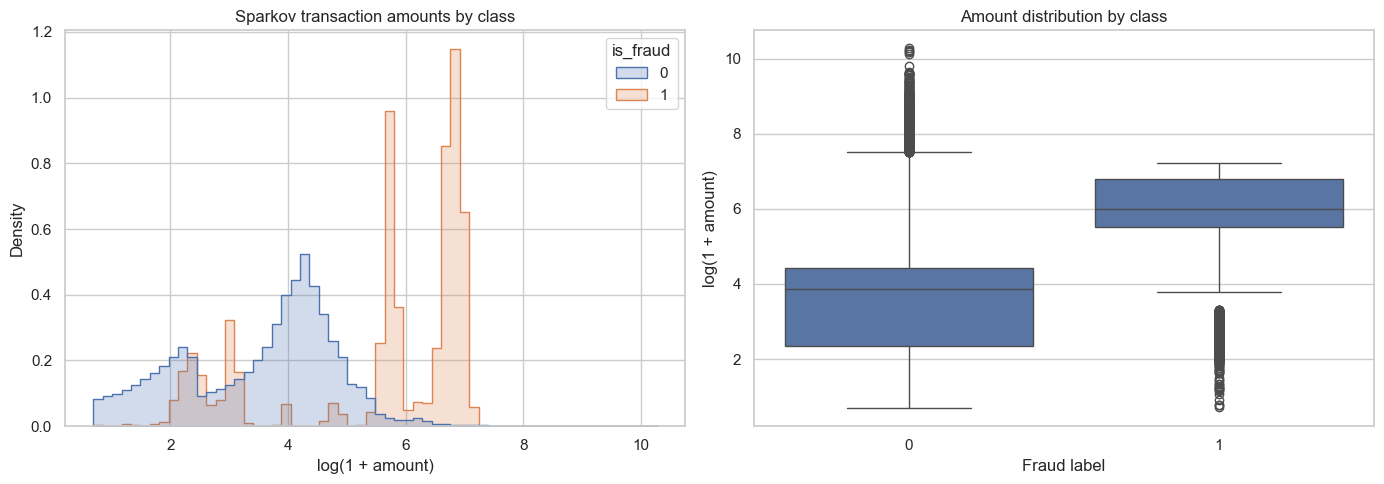

In [5]:
sparkov["transaction_datetime"] = pd.to_datetime(sparkov["trans_date_trans_time"], errors="coerce")
sparkov["amount_log"] = np.log1p(sparkov["amt"].clip(lower=0))

# transaction amount is compressed by log, large numbers are compressed, small numbers stay apart

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=sparkov, x="amount_log", hue="is_fraud", bins=60, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set(title="Sparkov transaction amounts by class", xlabel="log(1 + amount)")
sns.boxplot(data=sparkov, x="is_fraud", y="amount_log", ax=axes[1])
axes[1].set(title="Amount distribution by class", xlabel="Fraud label", ylabel="log(1 + amount)")
plt.tight_layout()

display(sparkov.groupby("is_fraud")["amt"].describe())

**Takeaway**
- Fraud transactions are much larger than non-fraud ones: the median fraud amount is 396.51 vs 47.28 for non-fraud, and the mean is 531.32 vs 67.67

- Fraud amounts are concentrated in a few narrow peaks (around log(1 + amount) of 2-3, 5.8 and 6.9), while non-fraud amounts are spread out. The highest fraud amount is only 1,376.04 vs 28,948.90 for non-fraud

- So amount is a very strong signal in Sparkov, but the narrow peaks may be simulated rules specifically in the Sparkov dataset rather than real fraud behaviour, which is one reason we also use IEEE-CIS

,transactions,frauds,fraud_rate_pct
period,,,
2019-01-01,52525,506,0.963351
2019-02-01,49866,517,1.036779
2019-03-01,70939,494,0.696373
2019-04-01,68078,376,0.552308
2019-05-01,72532,408,0.562510


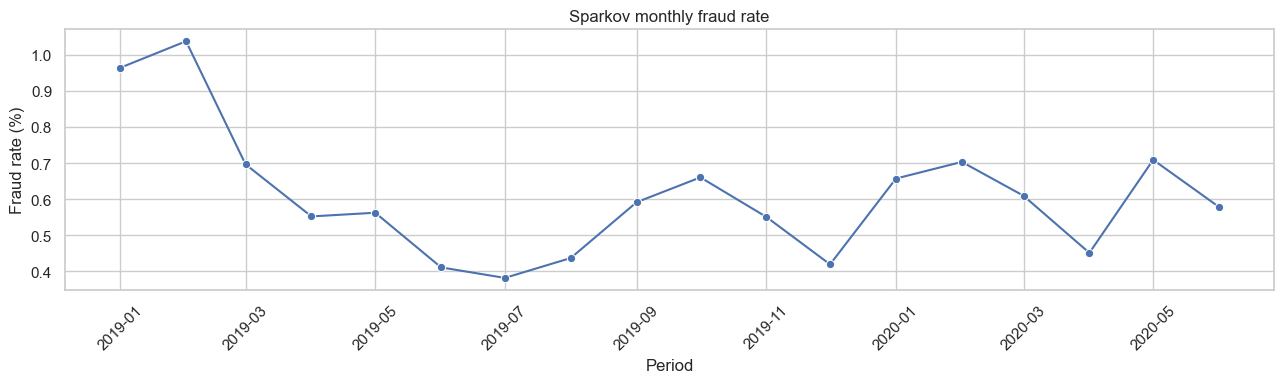

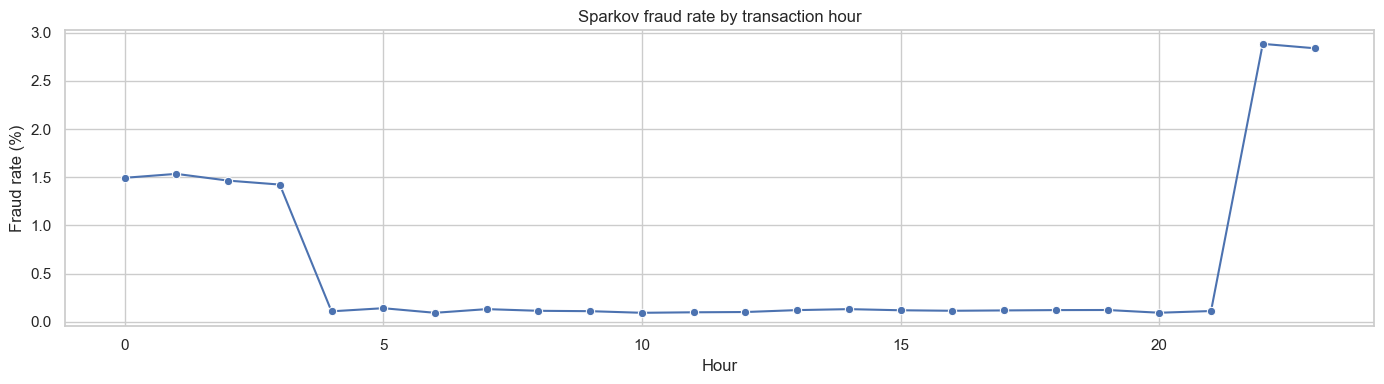

In [6]:
sparkov_monthly = plot_fraud_rate(
    sparkov, "is_fraud", "transaction_datetime",
    "Sparkov monthly fraud rate", period="M"
)
display(sparkov_monthly.head())

sparkov["hour"] = sparkov["transaction_datetime"].dt.hour
hourly = sparkov.groupby("hour")["is_fraud"].agg(transactions="size", frauds="sum")
hourly["fraud_rate_pct"] = hourly["frauds"] / hourly["transactions"] * 100

fig, axes = plt.subplots(figsize=(14, 4))
sns.lineplot(data=hourly, x=hourly.index, y="fraud_rate_pct", marker="o", ax=axes)
axes.set(title="Sparkov fraud rate by transaction hour", xlabel="Hour", ylabel="Fraud rate (%)")

plt.tight_layout()

**Takeaway**
- The monthly fraud rate changes over time, from about 0.4% (July 2019) to about 1.0% (January and February 2019) => fraud is not stationary, so we validate forward in time instead of using random splits

- Fraud is concentrated at night: the fraud rate is about 2.9% at 22:00 and 23:00 and about 1.5% between 00:00 and 03:00, but only about 0.1% between 04:00 and 21:00. Since the jump is sharp, this may be something simulated since Sparkov is a synthetic dataset

#### Merchant Category & Card activity

,category,transactions,frauds,fraud_rate,fraud_rate_pct
11,shopping_net,97543,1713,0.017561,1.756149
8,misc_net,63287,915,0.014458,1.445795
4,grocery_pos,123638,1743,0.014098,1.409761
12,shopping_pos,116672,843,0.007225,0.722538
2,gas_transport,131659,618,0.004694,0.469394
9,misc_pos,79655,250,0.003139,0.313853
3,grocery_net,45452,134,0.002948,0.294817
13,travel,40507,116,0.002864,0.286370
0,entertainment,94014,233,0.002478,0.247835
10,personal_care,90758,220,0.002424,0.242403


,cc_num,transactions,frauds,fraud_rate,total_amount,fraud_rate_pct
28,571365235126,3123,10,0.003202,191918.03,0.320205
943,4512828414983801773,3123,0,0.000000,172868.53,0.000000
222,36722699017270,3119,7,0.002244,280008.05,0.224431
272,213112402583773,3117,0,0.000000,179368.37,0.000000
531,3545109339866548,3113,0,0.000000,150914.97,0.000000
869,6534628260579800,3112,15,0.004820,163214.11,0.482005
822,6011367958204270,3110,0,0.000000,296436.73,0.000000
452,2720433095629877,3107,16,0.005150,164002.26,0.514966
828,6011438889172900,3106,14,0.004507,284013.50,0.450741
811,6011109736646996,3101,2,0.000645,278139.27,0.064495


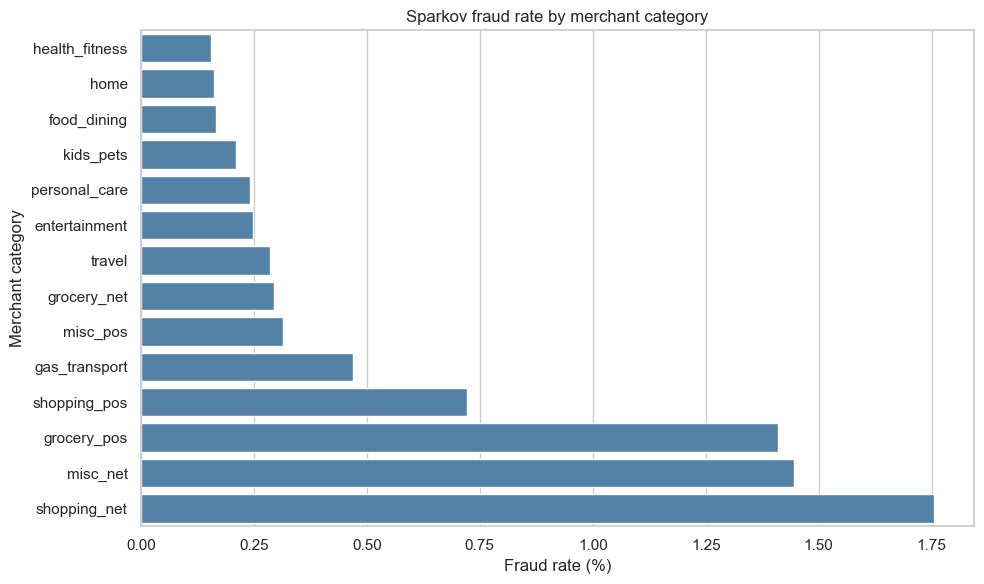

In [7]:
category_rates = fraud_rate_table(sparkov, "is_fraud", "category", min_count=500)
# Note: a min_count here is set, so small categories (eg. have 5 transactions, 4 of them are frauduluent, will be skewed)
# Feel free to edit ya

display(category_rates.head(15))

plt.figure(figsize=(10, 6))
plot_data = category_rates.sort_values("fraud_rate_pct", ascending=True)
sns.barplot(data=plot_data, x="fraud_rate_pct", y="category", color="steelblue")
plt.title("Sparkov fraud rate by merchant category")
plt.xlabel("Fraud rate (%)")
plt.ylabel("Merchant category")
plt.tight_layout()

card_activity = sparkov.groupby("cc_num").agg(
    transactions=("is_fraud", "size"),
    frauds=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean"),
    total_amount=("amt", "sum")
    ).reset_index()
card_activity["fraud_rate_pct"] = card_activity["fraud_rate"] * 100
display(card_activity.sort_values("transactions", ascending=False).head(15))

**Takeaway**
- Online shopping and misc categories have the highest fraud rates (`shopping_net` 1.76%, `misc_net` 1.45%), together with `grocery_pos` (1.41%). `health_fitness` and `home` have the lowest (about 0.15%)

- Each Sparkov card (`cc_num`) has a long history: the most active cards have over 3,000 transactions each, with 0 to 16 frauds => card-history features can be built directly from `cc_num`, unlike IEEE-CIS

#### Card-to-merchant distance

In [8]:
geo = sparkov.copy()

lat1 = np.radians(geo["lat"])
lon1 = np.radians(geo["long"])
lat2 = np.radians(geo["merch_lat"])
lon2 = np.radians(geo["merch_long"])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1)
    * np.cos(lat2)
    * np.sin(dlon / 2) ** 2
)

geo["card_merchant_distance_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(a))
)

display(
    geo.groupby("is_fraud")["card_merchant_distance_km"]
    .describe()
)

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,76.113756,29.119051,0.022255,55.332701,78.233012,98.504498,152.117173
1,7506.0,76.268330,28.752602,0.738769,55.632890,77.931954,98.391090,144.522410


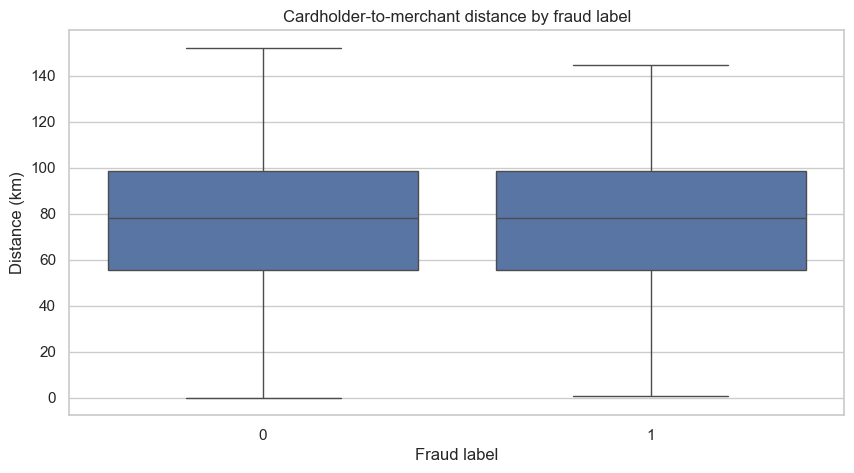

In [9]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=geo,
    x="is_fraud",
    y="card_merchant_distance_km",
    showfliers=False
)

plt.title("Cardholder-to-merchant distance by fraud label")
plt.xlabel("Fraud label")
plt.ylabel("Distance (km)")
plt.show()

In [10]:
distance_auc = roc_auc_score(
    geo["is_fraud"],
    geo["card_merchant_distance_km"]
)

print(f"Distance ROC-AUC: {distance_auc:.4f}")

Distance ROC-AUC: 0.5008


In [11]:
geo["distance_log1p"] = np.log1p(
    geo["card_merchant_distance_km"]
)

distance_log_auc = roc_auc_score(
    geo["is_fraud"],
    geo["distance_log1p"]
)

print(f"Log-distance ROC-AUC: {distance_log_auc:.4f}")

Log-distance ROC-AUC: 0.5008


**Takeaway**
* ROC-AUC for both Distance and Log-distance remains close to 0.5 (both are are 0.5008)
* as such, distance provides little standalone discrimination

### IEEE-CIS

#### Identity table
The identity table (`train_identity.csv`) has device and network information (e.g. `DeviceType`, `DeviceInfo`, `id_01` to `id_38`) for some transactions. We join it to the transactions on `TransactionID` (left join, so transactions without an identity record are kept) and check:

1. how many transactions have an identity record and how their fraud rate compares

2. which product types have identity records

3. whether the share of transactions with an identity record changes over time

In [12]:
# load the identity table and join it to the transactions
IEEE_IDENTITY_PATH = DATA_DIR / "train_identity.csv"
ieee_identity = read_csv_checked(IEEE_IDENTITY_PATH)

ieee = ieee.merge(ieee_identity, on="TransactionID", how="left", validate="one_to_one")
ieee["has_identity"] = ieee["TransactionID"].isin(ieee_identity["TransactionID"])

print("identity table:", ieee_identity.shape)
print("transactions with an identity record:", round(ieee["has_identity"].mean() * 100, 1), "%")


# 1. fraud rate with and without an identity record
display(fraud_rate_table(ieee, "isFraud", "has_identity"))

# share of all fraud transactions that have an identity record
fraud_with_identity = ieee.loc[ieee["isFraud"] == 1, "has_identity"].mean() * 100
print("fraud transactions with an identity record:", round(fraud_with_identity, 1), "%")


# 2. share of transactions with an identity record for each product type
identity_by_product = ieee.groupby("ProductCD")["has_identity"].mean() * 100
display(identity_by_product.round(1).to_frame("with identity %"))


# 3. share of transactions with an identity record in each 30-day period
# (also the share of W transactions, since W never has an identity record)
period = (ieee["TransactionDT"] // 86400) // 30
identity_by_period = pd.DataFrame({
    "transactions": ieee.groupby(period).size(),
    "with identity %": ieee.groupby(period)["has_identity"].mean() * 100,
    "W %": (ieee["ProductCD"] == "W").groupby(period).mean() * 100,
    "with identity, excluding W %": ieee[ieee["ProductCD"] != "W"].groupby(period)["has_identity"].mean() * 100
})
identity_by_period.index.name = "30-day period"
display(identity_by_period.round(1))

Reading ..\data\raw\train_identity.csv ...
identity table: (144233, 41)
transactions with an identity record: 24.4 %


,has_identity,transactions,frauds,fraud_rate,fraud_rate_pct
1,True,144233,11318,0.078470,7.847025
0,False,446307,9345,0.020939,2.093850


fraud transactions with an identity record: 54.8 %


,with identity %
ProductCD,
C,90.8
H,99.6
R,99.6
S,99.6
W,0.0


,transactions,with identity %,W %,"with identity, excluding W %"
30-day period,,,,
0,130968,43.6,54.7,96.2
1,89838,18.6,80.2,94.1
2,91768,18.9,79.9,93.8
3,98027,18.6,80.3,94.3
4,85303,17.7,81.6,96.1
5,86525,21.1,78.4,97.6
6,8111,18.1,81.6,98.5


**Takeaway**
- 24.4% of transactions have an identity record, but they contain 54.8% of all fraud transactions => the fraud rate is 7.8% with an identity record vs 2.1% without

- Identity records depend on the product type: `W` transactions never have one, while `C`, `H`, `R` and `S` almost always do (91-100%) => `has_identity` mostly repeats `ProductCD`, so it adds little once `ProductCD` is used

- The share with an identity record drops from 43.6% in the first 30 days to about 18-21% afterwards. This is because `W` grows from 54.7% to about 80% of transactions, while the share among non-`W` transactions stays at 94-99% => identity and device columns will look like they drift over time, but this comes from the product mix changing, not from fraud behaviour changing

#### Transaction amount, relative time
* `TransactionDT` is elapsed time, hence shown as relative days (and not calendar date)

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,569877.0,134.511665,239.395078,0.251,43.970,68.5,120.0,31937.391
1,20663.0,149.244779,232.212163,0.292,35.044,75.0,161.0,5191.000


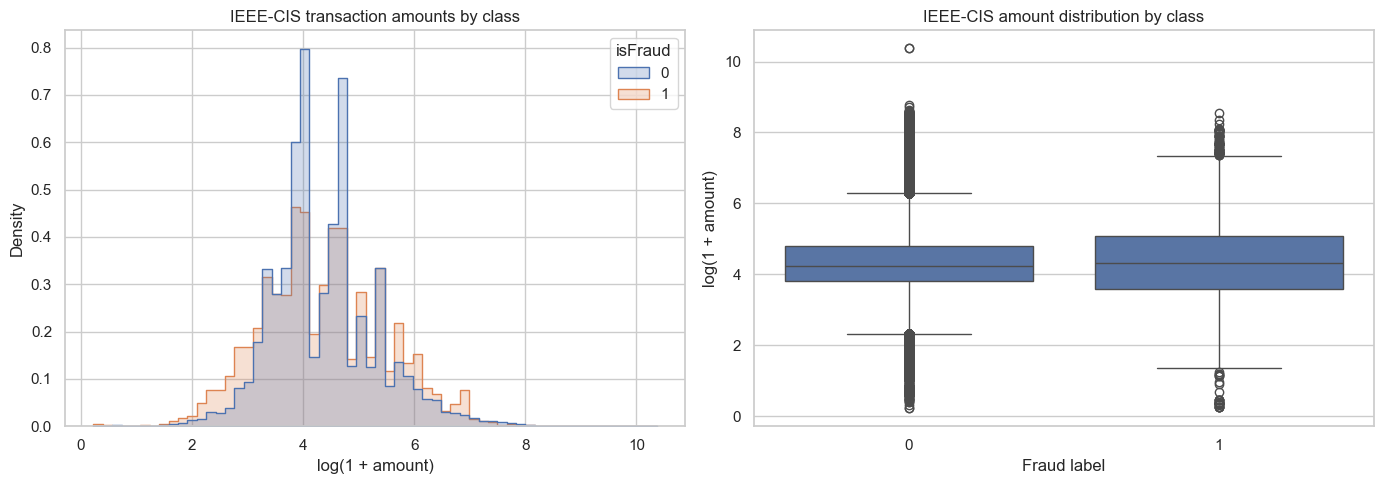

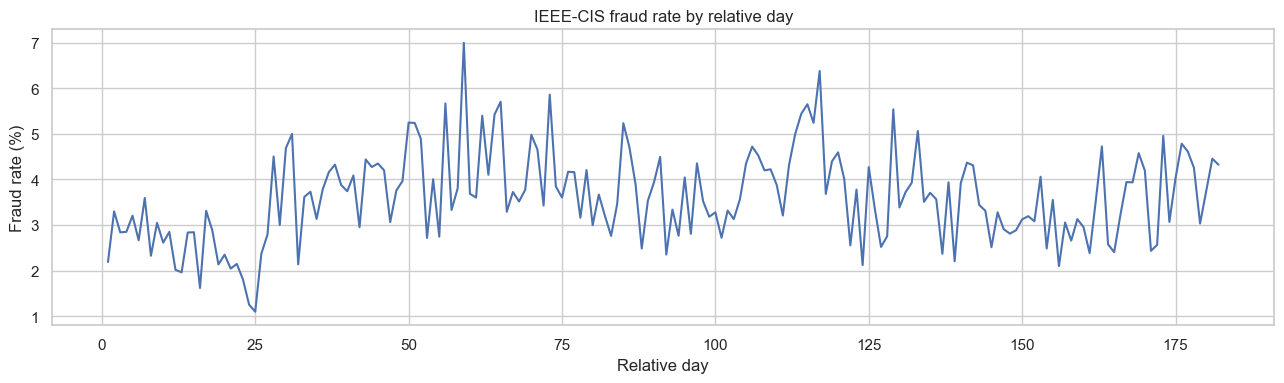

In [13]:
ieee["amount_log"] = np.log1p(ieee["TransactionAmt"].clip(lower=0))
ieee["relative_day"] = ieee["TransactionDT"] // 86400

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=ieee, x="amount_log", hue="isFraud", bins=60, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set(title="IEEE-CIS transaction amounts by class", xlabel="log(1 + amount)")
sns.boxplot(data=ieee, x="isFraud", y="amount_log", ax=axes[1])
axes[1].set(title="IEEE-CIS amount distribution by class", xlabel="Fraud label", ylabel="log(1 + amount)")
plt.tight_layout()
display(ieee.groupby("isFraud")["TransactionAmt"].describe())

ieee_daily = ieee.groupby("relative_day")["isFraud"].agg(transactions="size", frauds="sum")
ieee_daily["fraud_rate_pct"] = ieee_daily["frauds"] / ieee_daily["transactions"] * 100
plt.figure(figsize=(13, 4))
sns.lineplot(data=ieee_daily, x=ieee_daily.index, y="fraud_rate_pct")
plt.title("IEEE-CIS fraud rate by relative day")
plt.xlabel("Relative day")
plt.ylabel("Fraud rate (%)")
plt.tight_layout()

**Takeaway**
- Unlike Sparkov, fraud and non-fraud amounts overlap a lot in IEEE-CIS: the median fraud amount is 75.00 vs 68.50 for non-fraud, and the mean is 149.24 vs 134.51 => amount alone is a much weaker signal on real data

- The daily fraud rate moves between about 1% and 7%. It is lower in roughly the first 25 days (about 2-3%) and mostly between 3% and 5% afterwards => fraud changes over time here too

#### Fraud rate by categorical columns
- Compare fraud rates for `ProductCD`, `card1` to `card6` and `DeviceType` (from the identity table)

- Only values with at least 500 transactions are shown, so small groups do not give misleading fraud rates

,ProductCD,transactions,frauds,fraud_rate,fraud_rate_pct
0,C,68519,8008,0.116873,11.687269
3,S,11628,686,0.058996,5.899553
1,H,33024,1574,0.047662,4.766231
2,R,37699,1426,0.037826,3.782594
4,W,439670,8969,0.020399,2.039939


,card1,transactions,frauds,fraud_rate,fraud_rate_pct
6938,9917,919,306,0.332971,33.297062
10364,14276,894,252,0.281879,28.187919
7703,10876,750,186,0.248000,24.800000
2718,4504,974,210,0.215606,21.560575
7460,10568,925,190,0.205405,20.540541
6262,9026,2076,397,0.191233,19.123314
773,1976,928,177,0.190733,19.073276
6035,8755,1110,199,0.179279,17.927928
6715,9633,4158,742,0.178451,17.845118
983,2256,1343,235,0.174981,17.498138


,card2,transactions,frauds,fraud_rate,fraud_rate_pct
75,176.0,513,185,0.360624,36.062378
4,104.0,754,187,0.248011,24.801061
76,177.0,1642,396,0.241169,24.116931
41,142.0,1685,405,0.240356,24.035608
29,130.0,2746,657,0.239257,23.925710
358,459.0,677,135,0.199409,19.940916
195,296.0,2516,483,0.191971,19.197138
165,266.0,872,167,0.191514,19.151376
399,500.0,5045,911,0.180575,18.057483
428,529.0,754,136,0.180371,18.037135


,card3,transactions,frauds,fraud_rate,fraud_rate_pct
73,185.0,56346,7362,0.130657,13.065701
13,119.0,750,70,0.093333,9.333333
37,144.0,1252,112,0.089457,8.945687
36,143.0,899,28,0.031146,3.114572
42,150.0,521287,12807,0.024568,2.456804
38,146.0,1252,25,0.019968,1.996805
11,117.0,962,18,0.018711,1.871102
4,106.0,1571,24,0.015277,1.527689


,card4,transactions,frauds,fraud_rate,fraud_rate_pct
1,discover,6651,514,0.077282,7.728161
3,visa,384767,13373,0.034756,3.475610
2,mastercard,189217,6496,0.034331,3.433095
0,american express,8328,239,0.028698,2.869837


,card5,transactions,frauds,fraud_rate,fraud_rate_pct
33,137.0,11720,1725,0.147184,14.718430
105,223.0,936,83,0.088675,8.867521
34,138.0,19737,1682,0.085221,8.522065
54,162.0,4524,301,0.066534,6.653404
2,102.0,29105,1832,0.062945,6.294451
102,219.0,9924,571,0.057537,5.753728
82,197.0,1551,86,0.055448,5.544810
83,198.0,670,34,0.050746,5.074627
80,195.0,16945,681,0.040189,4.018885
106,224.0,81513,3152,0.038669,3.866868


,card6,transactions,frauds,fraud_rate,fraud_rate_pct
1,credit,148986,9950,0.066785,6.678480
2,debit,439938,10674,0.024263,2.426251


,DeviceType,transactions,frauds,fraud_rate,fraud_rate_pct
1,mobile,55645,5657,0.101662,10.166232
0,desktop,85165,5554,0.065215,6.521458


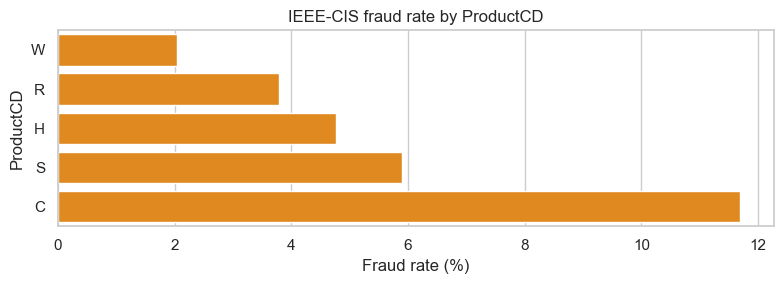

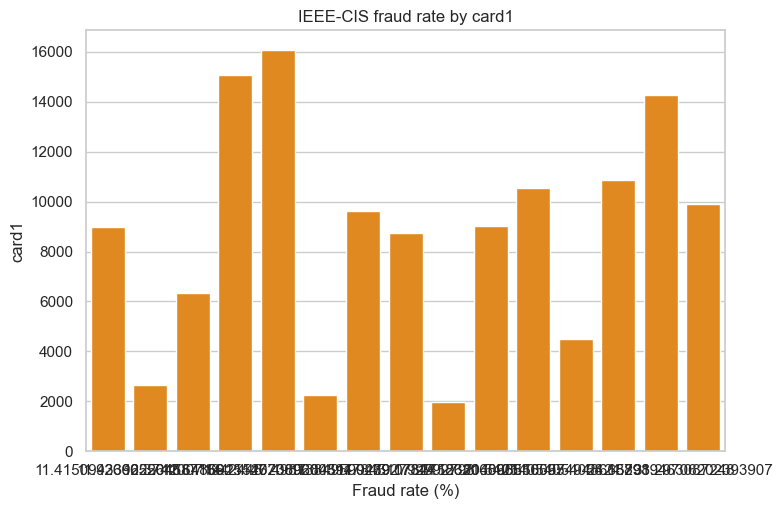

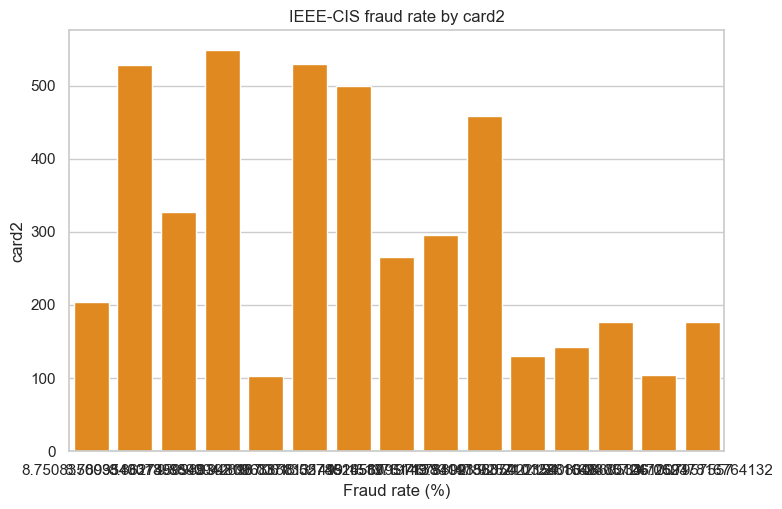

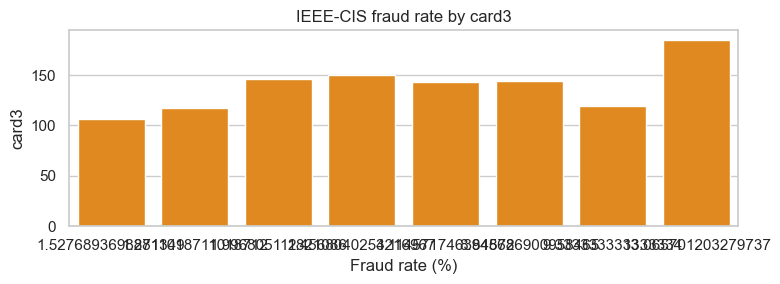

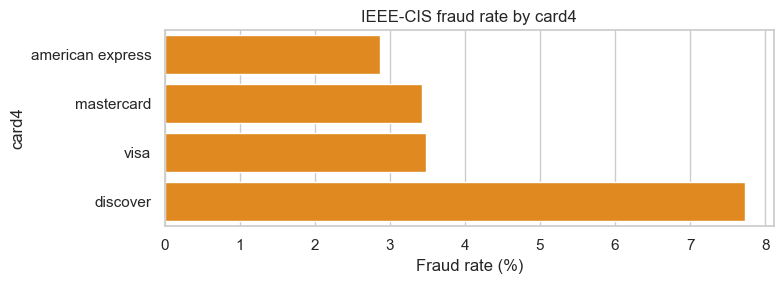

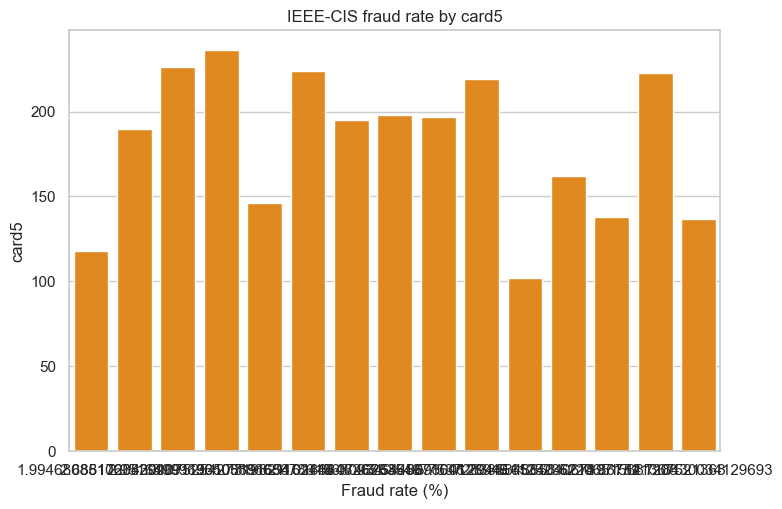

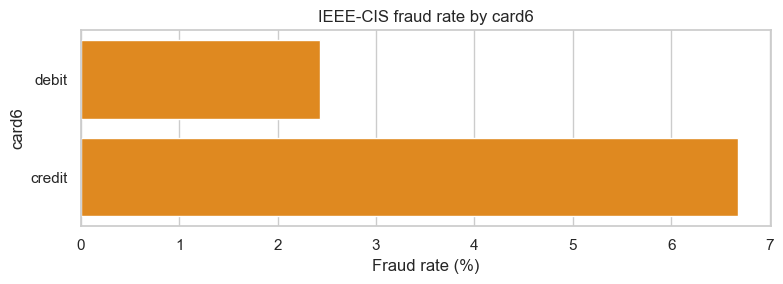

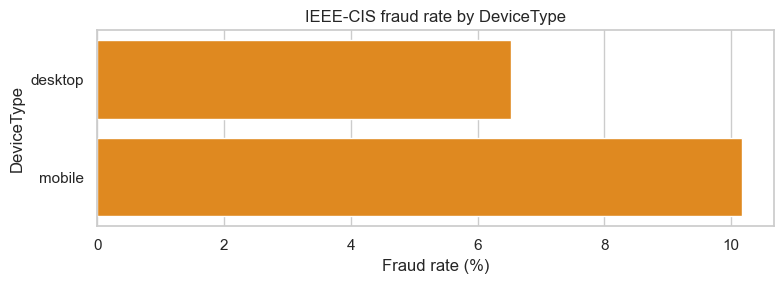

In [14]:
# Compare fraud rates for selected categorical IEEE-CIS variables.
for column in ["ProductCD", "card1", "card2", "card3", "card4","card5", "card6", "DeviceType"]:
    if column not in ieee.columns:
        continue
    rates = fraud_rate_table(ieee, "isFraud", column, min_count=500)
    display(rates.head(15))
    plt.figure(figsize=(8, max(3, 0.35 * len(rates.head(15)))))
    sns.barplot(data=rates.head(15).sort_values("fraud_rate_pct"), x="fraud_rate_pct", y=column, color="darkorange")
    plt.title(f"IEEE-CIS fraud rate by {column}")
    plt.xlabel("Fraud rate (%)")
    plt.tight_layout()

**Takeaway**
- `ProductCD = C` has the highest fraud rate (11.7%) and `W` the lowest (2.0%), even though `W` makes up about 74% of transactions

- Credit cards have a higher fraud rate than debit cards (6.7% vs 2.4%), and `discover` is higher than the other card networks (7.7% vs 2.9-3.5%)

- Mobile transactions have a higher fraud rate than desktop ones (10.2% vs 6.5%), but `DeviceType` only exists for the 24% of transactions with an identity record

- Some `card1` and `card2` values have very high fraud rates (up to 33% and 36%), but this does not always mean the whole value is risky. One stolen card can have many fraud transactions, so a few stolen cards can make a value’s fraud rate look high (e.g. for card1 = 9917, just 5 of its 204 cards made 64% of its fraud)

#### Explore columns for card ID reconstruction
IEEE-CIS has no card number, but card-history features need to know which transactions belong to the same card, so we check which columns could help group transactions from the same card

1. **Card and address columns**: check how many transactions share each value

2. **D columns**: check what the D columns look like, since they are timedelta columns

3. **D1 against day**: plot `D1` against the day for one `card1 + addr1` group to see if `D1` is the days since the card was first used

4. **What the other D columns measure**: use the `card1 + addr1 + D1n` key to test every D column, to find which ones can check the key in notebook 03

In [15]:
# 1. Card and address columns

card_cols = [f"card{i}" for i in range(1, 7)] + ["addr1", "addr2"]

card_summary = pd.DataFrame({
    "unique values": ieee[card_cols].nunique(),
    "missing %": ieee[card_cols].isna().mean() * 100,
    "median txns per value": [ieee[col].value_counts().median() for col in card_cols],
    "max txns per value": [ieee[col].value_counts().max() for col in card_cols]
})
display(card_summary.round(2))


# 2. D columns

d_cols = [f"D{i}" for i in range(1, 16)]

d_summary = ieee[d_cols].agg(["min", "max", "median"]).T
d_summary["missing %"] = ieee[d_cols].isna().mean() * 100
display(d_summary.round(1))

,unique values,missing %,median txns per value,max txns per value
card1,13553,0.00,4.0,14932
card2,500,1.51,176.0,48935
card3,114,0.27,10.0,521287
card4,4,0.27,98772.5,384767
card5,119,0.72,13.0,296546
card6,4,0.27,74508.0,439938
addr1,332,11.13,3.0,46335
addr2,74,11.13,3.5,520481


,min,max,median,missing %
D1,0.0,640.0,3.0,0.2
D2,0.0,640.0,97.0,47.5
D3,0.0,819.0,8.0,44.5
D4,-122.0,869.0,26.0,28.6
D5,0.0,819.0,10.0,52.5
D6,-83.0,873.0,0.0,87.6
D7,0.0,843.0,0.0,93.4
D8,0.0,1707.8,37.9,87.3
D9,0.0,1.0,0.7,87.3
D10,0.0,876.0,15.0,12.9


**Takeaway**
- None of the card columns can identify a card on its own. `card1` has the most values (13,553) but 1 value still covers 14,932 transactions, so it is more like an issuer code than a card number. `card2` to `card6` are even more general (e.g. `card4` and `card6` only have 4 values)

- Most D columns are whole numbers of days (except `D8` and `D9`, which have decimals) and many are heavily missing. `D1` is almost never missing (0.2%) and ranges from 0 to 640

- If `D1` is the number of days since the card was first used, then `D1n = day - D1` should stay the same for every transaction of the same card => we check this below by plotting `D1` against the day for one `card1 + addr1` group. Each card should then show up as its own diagonal line with a slope of 1

largest card1 + addr1 group: (np.int64(17188), np.float64(299.0))
transactions: 5885
distinct D1n values: 499

plotted group transactions: 115
plotted group possible cards (distinct D1n values): 11


,transactions,frauds,first day,last day
D1n,,,,
-5.0,60,60,9,118
-147.0,42,0,40,181
19.0,3,0,19,19
-6.0,2,0,57,166
27.0,2,0,27,27
12.0,1,0,12,12
50.0,1,0,50,50
62.0,1,0,62,62
78.0,1,0,78,78


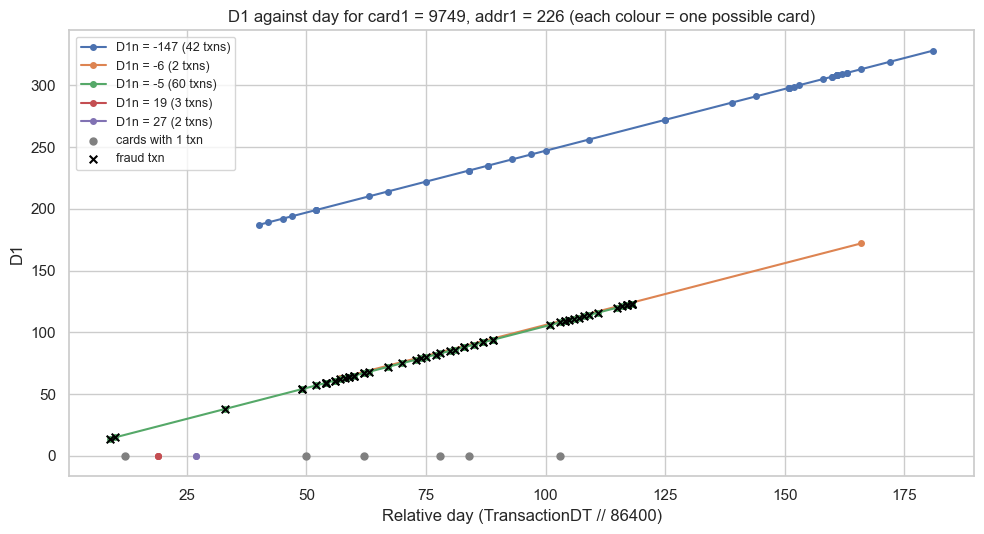

In [16]:
# 3. D1 against day

# relative_day was already calculated in the transaction amount section above
ieee["D1n"] = ieee["relative_day"] - ieee["D1"]

# number of transactions and possible cards (distinct D1n values) in each card1 + addr1 group
groups = ieee.groupby(["card1", "addr1"]).agg(txns=("D1n", "size"), possible_cards=("D1n", "nunique"))

largest = groups["txns"].idxmax()
print("largest card1 + addr1 group:", largest)
print("transactions:", groups.loc[largest, "txns"])
print("distinct D1n values:", groups.loc[largest, "possible_cards"])

# the largest group has too many cards to plot clearly, so pick a group with 10-30 possible cards
# and many transactions per card
readable = groups[groups["possible_cards"].between(10, 30)]
card1_value, addr1_value = (readable["txns"] / readable["possible_cards"]).idxmax()

group = ieee[(ieee["card1"] == card1_value) & (ieee["addr1"] == addr1_value)]

# list the possible cards (D1n values) in this group
cards_in_group = group.groupby("D1n").agg(
    transactions=("D1", "size"),
    frauds=("isFraud", "sum"),
    first_day=("relative_day", "min"),
    last_day=("relative_day", "max")
).sort_values("transactions", ascending=False)
cards_in_group = cards_in_group.rename(columns={"first_day": "first day", "last_day": "last day"})

print("\nplotted group transactions:", len(group))
print("plotted group possible cards (distinct D1n values):", len(cards_in_group))
display(cards_in_group)


# plot each possible card in its own colour, joining its transactions in time order
plt.figure(figsize=(10, 5.5))

for d1n, card in group.sort_values("relative_day").groupby("D1n"):
    if len(card) > 1:
        plt.plot(card["relative_day"], card["D1"], marker="o", markersize=4, linewidth=1.5,
                 label=f"D1n = {d1n:.0f} ({len(card)} txns)")
    else:
        # cards with only one transaction are shown as grey dots
        plt.scatter(card["relative_day"], card["D1"], color="grey", s=25)

# extra legend entries for the grey dots and the fraud markers
plt.scatter([], [], color="grey", s=25, label="cards with 1 txn")

fraud = group[group["isFraud"] == 1]
plt.scatter(fraud["relative_day"], fraud["D1"], marker="x", color="black", s=30, zorder=3, label="fraud txn")

plt.xlabel("Relative day (TransactionDT // 86400)")
plt.ylabel("D1")
plt.title(f"D1 against day for card1 = {card1_value}, addr1 = {addr1_value:.0f} (each colour = one possible card)")
plt.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

**Takeaway**
- Each possible card (each colour i.e. each `D1n` value) forms its own diagonal line, where `D1` goes up by one for every day, so `D1` does seem to be the days since the card was first used. The plotted group has 115 transactions from 11 possible cards: 5 cards with more than one transaction (coloured) and 6 cards with only one (grey dots). The `D1n = 19` and `D1n = 27` cards had all their transactions on the same day, so they show up as single coloured dots at `D1 = 0` instead of lines

- One `card1 + addr1` group can contain many different cards (499 possible cards in the largest group), so `card1 + addr1` alone is not enough, but `card1 + addr1 + D1n` can separate them

- One of the cards (`D1n = -5`, the line covered by black crosses) is labelled fraud on every one of its 60 transactions, from day 9 to day 118. The plot cannot tell us why (e.g. the card may only have been used by a fraudster), but it fits how the labels are defined by the competition host: a transaction with a reported chargeback is labelled fraud, and later transactions linked to it by the same user account, email address or billing address are labelled fraud too, while transactions with no report within 120 days are labelled legit ([Data Description thread](https://www.kaggle.com/c/ieee-fraud-detection/discussion/101203)) => fraud labels can cover whole cards, so a model with card-history features could learn "this card had fraud before" instead of real fraud patterns. We check how common this is in notebook 03 (Section 8)

- The dots along `D1 = 0` are not one card: each is a different card that was only seen on its first day (so `D1 = 0`). A flat row is not a card, only diagonal lines are

- The `D1n = -6` card (2 transactions, no fraud) sits almost on top of the `D1n = -5` fraud card because they were first used one day apart. The key keeps them separate since their `D1n` differs by 1, but this shows how close two different cards can be

Next, we use `card1 + addr1 + D1n` as a key and test what the other D columns measure. The competition host only describes `D1`-`D15` as "timedelta, such as days between previous transaction, etc." ([Data Description thread](https://www.kaggle.com/c/ieee-fraud-detection/discussion/101203)), without saying which column counts what. A "days since ..." counter can count from two kinds of events:
- **a fixed event** (like `D1`, the card's first use): then `day - D` should stay the same for every transaction of the card

- **the previous transaction**: then `D` should equal the gap (in days) to the card's previous transaction

So for every D column we check:
1. how often it matches the gap to the previous transaction with the same key (also only for gaps of 2+ days, since a value of 0 can match a gap of 0-1 day by coincidence)

2. how often `day - D` stays within 1 day across a key's transactions

3. how often it is equal to `D1`

4. how often it is missing

In [17]:
# 4. What the other D columns measure

# build the card1 + addr1 + D1n key (only for rows with D1)
has_d1 = ieee[ieee["D1"].notna()].copy()
has_d1["key"] = (has_d1["card1"].astype(str) + "_" + has_d1["addr1"].fillna(-1).astype(int).astype(str)
                 + "_" + has_d1["D1n"].astype(int).astype(str))

# sort each key's transactions by time
has_d1 = has_d1.sort_values(["key", "TransactionDT"])

# gap in days to the previous transaction with the same key
gap = has_d1["relative_day"] - has_d1.groupby("key")["relative_day"].shift()

# number of transactions in each key (only keys with more than one transaction can be checked)
txns_per_key = has_d1.groupby("key")["key"].transform("size")

d_screen = []

for col in d_cols:
    # (1) does the column match the gap to the previous transaction? (within 1 day)
    checkable = has_d1[col].notna() & gap.notna()
    matches_gap = ((has_d1[col] - gap)[checkable].abs() <= 1).mean() * 100

    # (1b) same check, but only for gaps of 2+ days (a value of 0 can match a gap of 0-1 day by coincidence)
    long_gap = checkable & (gap >= 2)
    matches_long_gap = ((has_d1[col] - gap)[long_gap].abs() <= 1).mean() * 100

    # (2) does day - D stay the same (within 1 day) across a key's transactions?
    multi = has_d1[(txns_per_key > 1) & has_d1[col].notna()].copy()
    multi["fixed_day"] = multi["relative_day"] - multi[col]
    spread = multi.groupby("key")["fixed_day"].agg(["size", "min", "max"])
    spread = spread[spread["size"] > 1]
    stays_fixed = ((spread["max"] - spread["min"]) <= 1).mean() * 100

    # how often the column is equal to D1
    both = ieee[col].notna() & ieee["D1"].notna()
    equals_d1 = (ieee.loc[both, col] == ieee.loc[both, "D1"]).mean() * 100

    d_screen.append({
        "D column": col,
        "missing %": ieee[col].isna().mean() * 100,
        "matches gap to previous txn %": matches_gap,
        "matches gap, gaps of 2+ days only %": matches_long_gap,
        "day - D stays fixed within key %": stays_fixed,
        "equals D1 %": equals_d1
    })

d_screen = pd.DataFrame(d_screen).set_index("D column")
display(d_screen.round(1))


# for D3, split the mismatches into the two directions
d3_minus_gap = (has_d1["D3"] - gap).dropna()

print("checkable transactions for D3:", len(d3_minus_gap))
print("D3 matches the gap (within 1 day):", round((d3_minus_gap.abs() <= 1).mean() * 100, 1), "%")
print("D3 > gap (another card mixed into the key):", round((d3_minus_gap > 1).mean() * 100, 1), "%")
print("D3 < gap (card split across keys):", round((d3_minus_gap < -1).mean() * 100, 1), "%")

,missing %,matches gap to previous txn %,"matches gap, gaps of 2+ days only %",day - D stays fixed within key %,equals D1 %
D column,,,,,
D1,0.2,40.9,18.0,100.0,100.0
D2,47.5,20.5,17.5,98.7,92.8
D3,44.5,94.6,93.2,13.5,20.5
D4,28.6,31.7,12.0,65.6,50.7
D5,52.5,78.3,76.3,10.4,19.8
D6,87.6,62.3,19.9,63.1,66.9
D7,93.4,79.3,63.6,28.8,43.0
D8,87.3,36.5,18.3,54.1,1.5
D9,87.3,82.5,0.0,64.7,3.6


checkable transactions for D3: 284351
D3 matches the gap (within 1 day): 94.6 %
D3 > gap (another card mixed into the key): 5.2 %
D3 < gap (card split across keys): 0.2 %


**Takeaway**
- **`D3` counts days since the card's previous transaction**: it matches the gap to the previous transaction with the same key for 94.6% of checkable transactions, and `day - D3` almost never stays fixed (13.5%). So `D3` can be used to check the key in notebook 03: if the key is correct, `D3` should match the gap
  - Most mismatches (5.2%) are where `D3` is larger than the gap, meaning another card has probably been mixed into the same key. Only 0.2% look like one card split across two keys
  - `D5` behaves similarly (78.3% match, 10.4% fixed) but matches less well and is missing more often (52.5% vs 44.5%), so we use `D3`

- **`D4`, `D10`, `D11` and `D15` count days since a fixed event**: `day - D` stays within 1 day in 64-75% of keys, while they only match the gap 23-33% of the time. This is less than the 100% for `D1`, so whatever they count from probably resets sometimes (or the key still mixes some cards), so they can only be used as rough checks. `D10`, `D15` and `D4` are missing the least (12.9%, 15.1% and 28.6%), so we use them as extra checks in notebook 03 (`D11` is 47.3% missing)

- **`D2` equals `D1` 92.8% of the time** and is missing for 47.5% of transactions, so it adds nothing beyond `D1`

- **Rest of the D columns are not useful here**: `D6`, `D7`, `D8`, `D9`, `D12`, `D13`, `D14` are 87-93% missing. Their gap matches look high, but most of their checkable transactions came 0-1 days after the previous one and their values are mostly 0 (`D9` is always between 0 and 1), so they "match" by coincidence. When we only look at gaps of 2+ days, their match drops a lot (e.g. `D9` 82.5% -> 0%, `D14` 62.7% -> 7.6%), except `D7` (which is 93% missing anyway), while `D3` stays at 93.2%

- `D1` is 100% fixed only because the groups themselves are built from `D1n`, so this is not evidence. It also matches the gap 40.9% of the time because on a card's second transaction, the gap since the first transaction is exactly `D1` (days since first use)

In `03_ieee_card_reconstruction.ipynb`, we use `card1 + addr1 + D1n` as the base key, `D3` to check it and `D4n`, `D10n` and `D15n` as extra checks, try to separate the mixed cards, and save the final card IDs

### Distribution shifts over time
* compare the earliest vs latest portion. KS Statistic measure the difference between 2 distributions. Large statistic = larger difference in distribution (* Need to use p value to measure statistical significance)

In [18]:
def early_late_ks(df, time_col, feature_cols, fraction=0.2):
    ordered = df.dropna(subset=[time_col]).sort_values(time_col)
    n = max(1, int(len(ordered) * fraction))
    early, late = ordered.head(n), ordered.tail(n)
    rows = []
    for col in feature_cols:
        if col not in df.columns or not pd.api.types.is_numeric_dtype(df[col]):
            continue
        x, y = early[col].dropna(), late[col].dropna()
        if len(x) < 20 or len(y) < 20:
            continue
        stat, p_value = ks_2samp(x, y)
        rows.append({"feature": col, "ks_statistic": stat, "p_value": p_value,
                     "early_median": x.median(), "late_median": y.median()})
    return pd.DataFrame(rows).sort_values("ks_statistic", ascending=False)

sparkov_shift = early_late_ks(
    sparkov, "transaction_datetime", ["amt", "city_pop", "lat", "long", "merch_lat", "merch_long"]
)
display(sparkov_shift)

ieee_shift = early_late_ks(
    ieee, "TransactionDT", ["TransactionAmt"] + [c for c in ieee.columns if c.startswith("C") or c.startswith("D")][:30]
)
display(ieee_shift.head(20))

,feature,ks_statistic,p_value,early_median,late_median
1,city_pop,0.004535,0.009632,2456.000000,2408.000000
4,merch_lat,0.003563,0.074164,39.355368,39.378282
2,lat,0.002919,0.218754,39.354300,39.371600
3,long,0.002156,0.582555,-87.461600,-87.476900
0,amt,0.002132,0.596434,47.650000,47.800000
5,merch_long,0.001835,0.774144,-87.421221,-87.431618


,feature,ks_statistic,p_value,early_median,late_median
9,C9,0.288803,0.000000e+00,0.000000,1.0
8,C8,0.241965,0.000000e+00,0.000000,0.0
10,C10,0.240043,0.000000e+00,0.000000,0.0
4,C4,0.190639,0.000000e+00,0.000000,0.0
15,D1,0.185067,0.000000e+00,0.000000,14.0
20,D6,0.180992,3.849771e-216,0.000000,0.0
13,C13,0.174086,0.000000e+00,1.000000,3.0
27,D13,0.169169,8.896882e-152,0.000000,0.0
29,D15,0.152378,0.000000e+00,42.000000,73.0
28,D14,0.141814,3.197766e-113,0.000000,0.0


**Takeaway**
- Sparkov barely changes over time (every KS statistic is below 0.005, and only `city_pop` has a p-value below 0.05 (0.0096))

- IEEE-CIS shifts much more: e.g. `C9` (0.29), `C8` (0.24), `C10` (0.24) and `D1` (0.19). Part of this is expected for the D columns, since they count days since an earlier event and keep growing as the data goes on (e.g. the median `D1` goes from 0 to 14 and `D15` from 42 to 73), so it is not necessarily a change in fraud behaviour

- Since M2 (sliding-window retraining) is meant to handle drift, testing on both IEEE-CIS and Sparkov will give a fair check of whether it helps